# Giants and moons

This notebook covers giant planets with cloud classes, colours (from atmospheric composition) and jets, cloud tops on the grid, rings, moon systems drawn from formation outcomes, moons built as worlds with tides, eclipses, planetshine and subsurface oceans, the `habitable_moon` archetype, the Solar System check, the system diagram and 3D scene, and the command line.

Run it from the `notebooks/` folder after `pip install -e ".[dev,notebooks,globe]"`. Worlds are built at preview resolution (10k cells), so the whole notebook runs in a few minutes.

In [1]:
%matplotlib inline
import os
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

from worldgen import generate, generate_world, save_world
from worldgen.giants import moon_world, rebuilt_parent_spec
from worldgen.render import plot_map
from worldgen.render.system import plot_system
from worldgen.render.system_scene import system_scene
from worldgen.report import format_report
from worldgen.spec import PlanetSpec

out = Path(tempfile.mkdtemp(prefix="worldgen_giants_"))


def section(report, title):
    """Return one titled section of a report."""
    lines = report.splitlines()
    start = lines.index(title)
    end = next((i for i in range(start + 1, len(lines)) if lines[i] == ""), len(lines))
    return "\n".join(lines[start:end])

## 1. Jupiter and the Galilean moons

A giant is given by its mass, radius and envelope fraction; the four moons are listed with their masses, radii, water fractions and orbits in planet radii (JPL and NSSDC values). Listed moons replace the drawn ones.

In [2]:
JUPITER = {
    "name": "Jupiter", "seed": 1, "star": {"mass_msun": 1.0, "age_gyr": 4.6},
    "orbit": {"semi_major_axis_au": 5.2, "eccentricity": 0.048, "obliquity_deg": 3.1, "rotation_period_h": 9.93},
    "body": {"mass_mearth": 317.8, "radius_rearth": 11.21, "envelope_mass_fraction": 0.9},
    "system": {"moons": [
        {"name": "Io", "mass_mearth": 0.01496, "radius_rearth": 0.286, "semi_major_axis_rp": 6.03, "eccentricity": 0.0041},
        {"name": "Europa", "mass_mearth": 0.00804, "radius_rearth": 0.245, "water_mass_fraction": 0.08,
         "semi_major_axis_rp": 9.6, "eccentricity": 0.0094},
        {"name": "Ganymede", "mass_mearth": 0.0248, "radius_rearth": 0.413, "water_mass_fraction": 0.45,
         "semi_major_axis_rp": 15.3, "eccentricity": 0.0013},
        {"name": "Callisto", "mass_mearth": 0.018, "radius_rearth": 0.378, "water_mass_fraction": 0.5,
         "semi_major_axis_rp": 26.9, "eccentricity": 0.0074},
    ]},
}
jupiter = generate_world(PlanetSpec.model_validate(JUPITER), "preview")
report = format_report(jupiter.state)
for title in ("Interior", "Appearance", "Moons and rings"):
    print(section(report, title), end="\n\n")

Interior
  structure                   fluid envelope, no solid surface
  internal heat               7.02 W/m², 4.5e+17 W (cooling since formation)  [heuristic]
  magnetic field              yes  [derived]

Appearance
  cloud class                 Sudarsky I  [derived]
  effective temperature       125 K (internal 105 K, 7.02 W/m²)  [heuristic]
  Bond albedo                 0.46  [derived]
  heavy elements              1.73× protosolar C/H  [heuristic]
  visible cloud               ammonia ice, base 0.58 bar; tropospheric haze τ 0 at 800 nm  [heuristic]
  colour                      #c2bcae (zones #cbcdc7, belts #b9a88f; brightness 0.50)  [heuristic]
  jets                        23 alternating, prograde at the equator (speed scale 14 m/s, Rhines length 7,605 km)  [heuristic]

Moons and rings
  stable moon orbits          out to 18,200,536 km (255 planet radii) prograde, 25,278,523 km retrograde  [heuristic]
  ring–moon boundary          2.90 planet radii for icy, 2.25 for rocky mater

The cloud tops are a stored model evaluated wherever a map or globe asks: bands between the jets, vortices drawn from the JunoCam statistics, polar cyclones. Giants map `clouds`, `temperature`, `winds`, `bands`, `vortices` and `relief`.

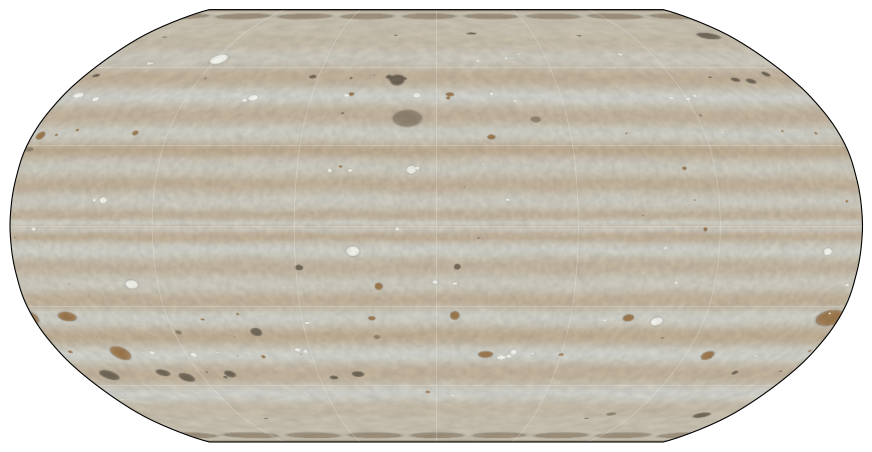

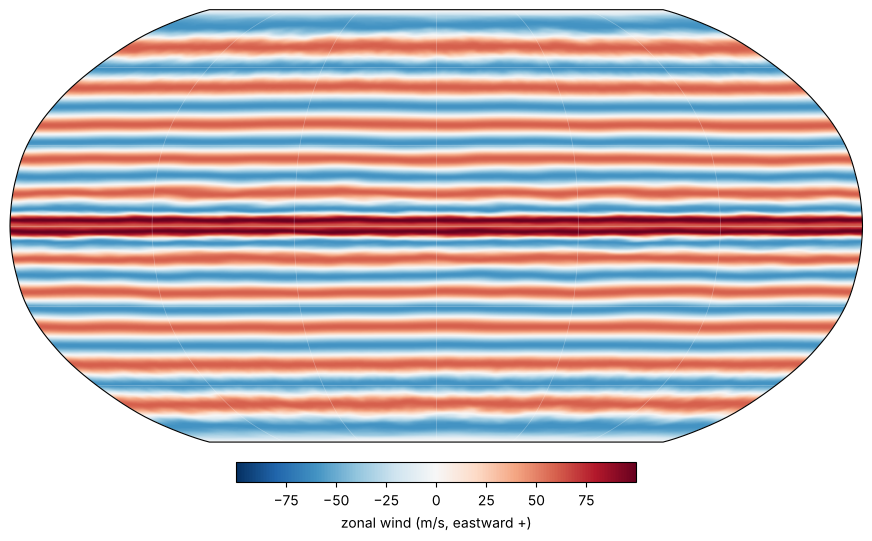

In [3]:
for field in ("clouds", "winds"):
    plot_map(jupiter, field, "robinson", width=1100, title="")
    plt.show()

## 2. Saturn with drawn rings and moons

Without listed moons the system is drawn. Saturn's ring temperature falls in the 60–80 K window, so it can hold broad icy rings; its regular moons come from the outcomes of Sasaki et al. (2010) without a gap in the nebula (one large moon), and ring-born moons spread outward from the ring edge (Crida & Charnoz 2012).

In [4]:
SATURN = {
    "name": "Saturn", "seed": 1, "star": {"mass_msun": 1.0, "age_gyr": 4.6},
    "orbit": {"semi_major_axis_au": 9.54, "obliquity_deg": 26.7, "rotation_period_h": 10.66},
    "body": {"mass_mearth": 95.2, "radius_rearth": 9.45, "envelope_mass_fraction": 0.85},
}
saturn = generate_world(PlanetSpec.model_validate(SATURN), "preview")
print(section(format_report(saturn.state), "Moons and rings"))

Moons and rings
  stable moon orbits          out to 23,249,517 km (386 planet radii) prograde, 32,290,996 km retrograde  [heuristic]
  ring–moon boundary          2.30 planet radii for icy, 1.78 for rocky material  [heuristic]
  synchronous orbit           1.86 planet radii
  largest surviving moon      no tidal limit
  moons                       drawn, Saturnian architecture (no gap in the nebula): 2 regular, 9 ring-born  [heuristic]
  Saturn I                    1.98e-06 M⊕, 122 km radius, 2.4 planet radii, 0.659 days, ring-born
  Saturn II                   4.1e-06 M⊕, 160 km radius, 2.5 planet radii, 0.683 days, ring-born
  Saturn III                  1.18e-05 M⊕, 225 km radius, 2.6 planet radii, 0.719 days, ring-born
  Saturn IV                   1.85e-05 M⊕, 257 km radius, 2.7 planet radii, 0.773 days, ring-born
  Saturn V                    3.07e-05 M⊕, 295 km radius, 2.9 planet radii, 0.854 days, ring-born
  Saturn VI                   6.73e-05 M⊕, 402 km radius, 3.2 planet r

Colour comes from the atmosphere. Saturn's envelope is about four times richer in heavy elements than Jupiter's and colder, so its ammonia cloud forms deeper (about 2 bar against 0.6) under a thicker haze that mutes the belts; Jupiter's chromophores show in brown belts. The report gives the metallicity, the visible cloud and its haze.

Jupiter
  cloud class                 Sudarsky I  [derived]
  effective temperature       125 K (internal 105 K, 7.02 W/m²)  [heuristic]
  Bond albedo                 0.46  [derived]
  heavy elements              1.73× protosolar C/H  [heuristic]
  visible cloud               ammonia ice, base 0.58 bar; tropospheric haze τ 0 at 800 nm  [heuristic]
  colour                      #c2bcae (zones #cbcdc7, belts #b9a88f; brightness 0.50)  [heuristic]
  jets                        23 alternating, prograde at the equator (speed scale 14 m/s, Rhines length 7,605 km)  [heuristic]

Saturn
  cloud class                 Sudarsky I  [derived]
  effective temperature       95 K (internal 82 K, 2.6 W/m²)  [heuristic]
  Bond albedo                 0.46  [derived]
  heavy elements              6.77× protosolar C/H  [heuristic]
  visible cloud               ammonia ice, base 1.8 bar; tropospheric haze τ 24 at 800 nm  [heuristic]
  colour                      #c3b7a0 (zones #c6bca8, belts #c0b198; brightn

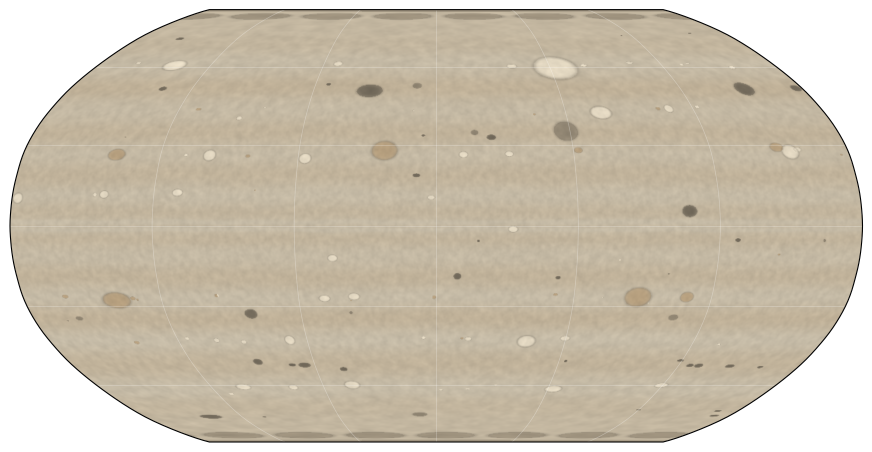

In [5]:
for world in (jupiter, saturn):
    print(world.state.name, section(format_report(world.state), "Appearance").split("\n", 1)[1], sep="\n", end="\n\n")
plot_map(saturn, "clouds", "robinson", width=1100, title="")
plt.show()

The diagram puts the planet's surface at 1 and each further unit ten times farther, so the rings and the outer moons share one figure. The limits are the icy and rocky Roche limits, the synchronous orbit, the outer limits for stable prograde and retrograde orbits and the Hill radius. The edge-on view shows the spin axis tilted by the obliquity.

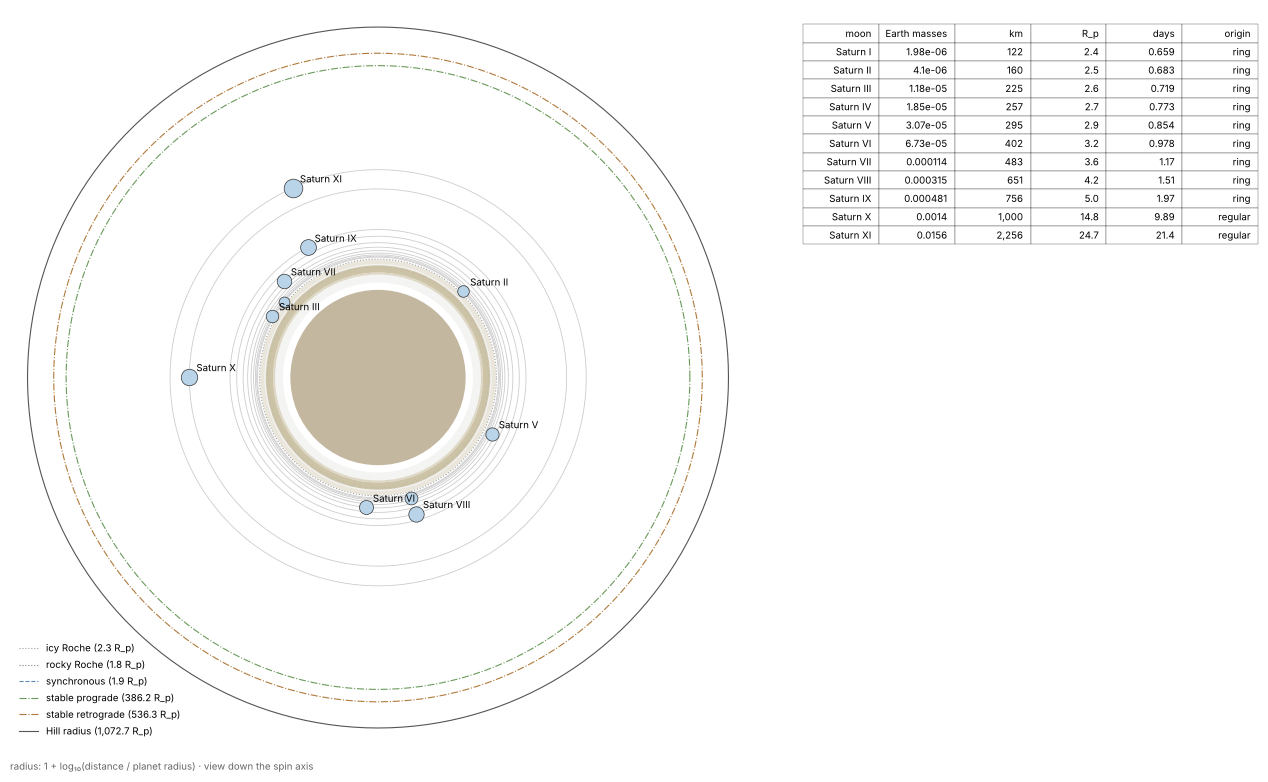

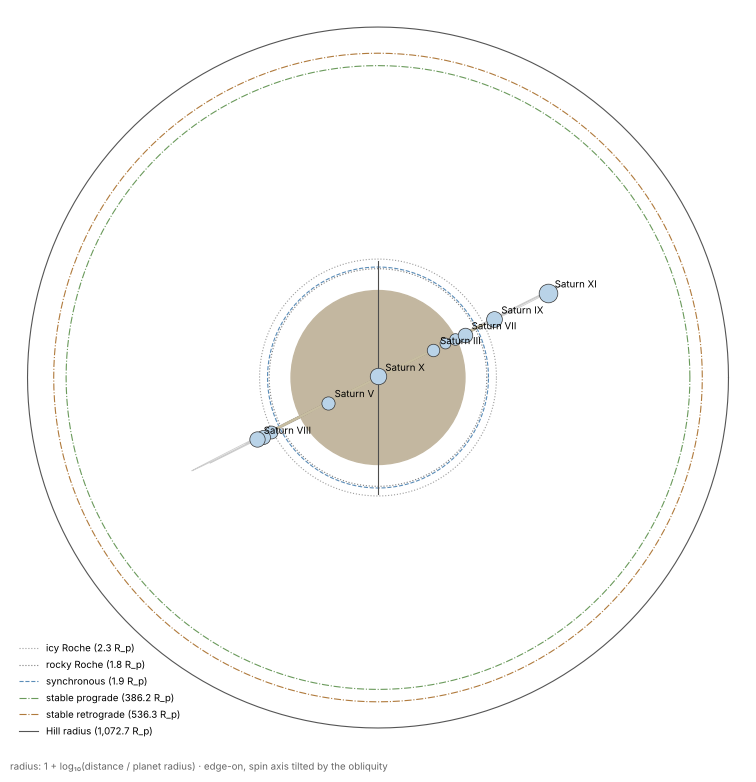

In [6]:
plot_system(saturn, view="top");
plot_system(saturn, view="edge", table=False);

## 3. An ice giant with a captured moon

Every giant gets one deep encounter with a binary; the binary-exchange capture (Williams & Zugger 2024) and the survival of the loose orbit (Porter & Grundy 2011) decide whether a moon stays. This Neptune keeps a retrograde moon of Triton's size, which circularised and decayed inward by tides.

Neptune VIII: 0.0019 Earth masses, 10.4 planet radii, retrograde


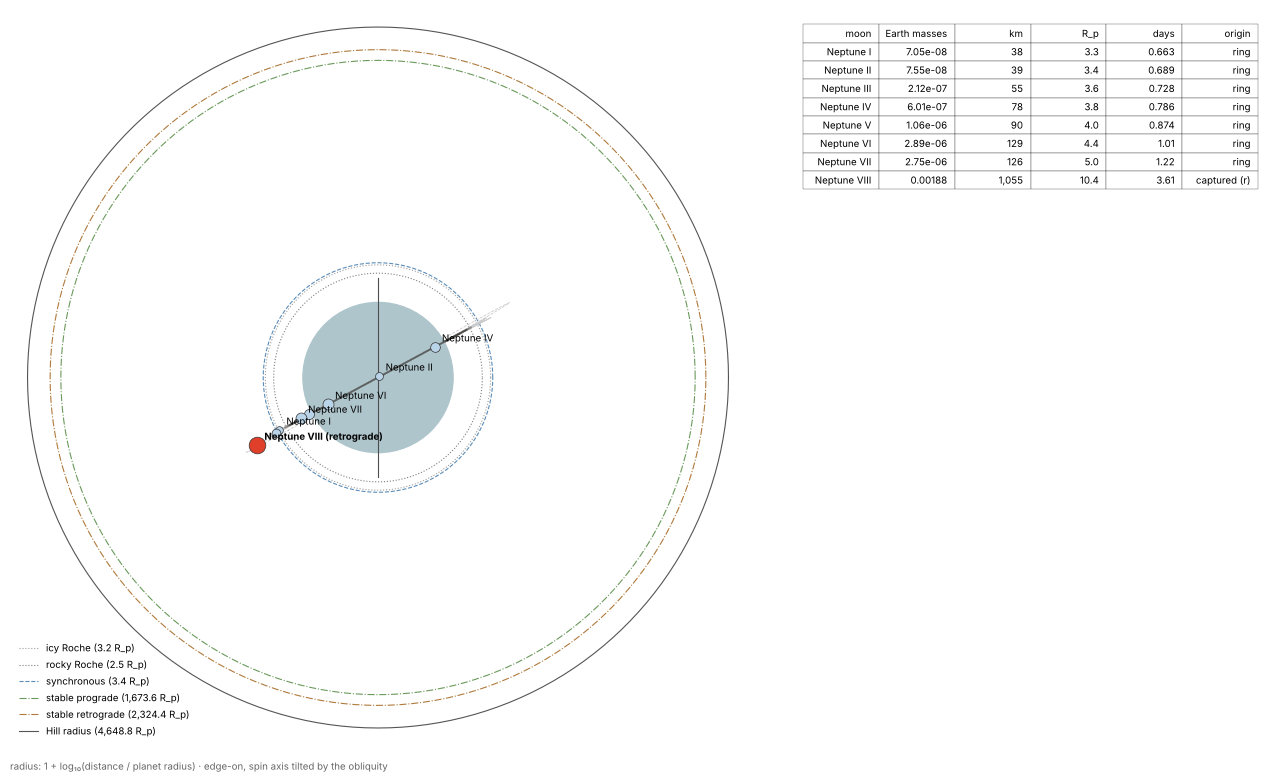

In [7]:
sys.path.insert(0, "../scripts")
from validate_solar_system import giant_spec

neptune = generate(giant_spec("Neptune", seed=4))[0]
for m in neptune.system.moons:
    if m.origin == "captured":
        print(f"{m.name}: {m.mass_kg / 5.9722e24:.2g} Earth masses, {m.semi_major_axis_m / neptune.bulk.radius_m:.1f} "
              f"planet radii, {'retrograde' if m.retrograde else 'prograde'}")
plot_system(neptune, view="edge", highlight="Neptune VIII");

## 4. Europa as a world

A moon becomes a world on request. It inherits the star and the planet's orbit, is locked to the planet, and its climate gets the eclipses, the planet's reflected light and glow, and tidal heat. Kept in the planet's saved folder, it is loaded instead of rebuilt next time, and the report, the CLI and the 3D scene find it.

In [8]:
folder = save_world(jupiter, out / "jupiter")
europa = moon_world(jupiter, 1, "preview", folder=folder)
io = moon_world(jupiter, 0, "preview", folder=folder)
report = format_report(europa.state)
print(section(report, "Parent planet"), end="\n\n")
print(section(report, "Water"), end="\n\n")
print([row for row in format_report(io.state).splitlines() if "tidal" in row])

Parent planet
  parent                      Jupiter, 317.8 M⊕, 11.2 R⊕  [user]
  orbit about the parent      685,622 km (9.6 parent radii), e = 0.0094  [user]
  period about the parent     3.668 days
  stable limit                255 parent radii  [heuristic]
  fluid Roche limit           1.82 parent radii
  parent rotation             9.93 h  [user]
  starlight                   0.0371 × Earth's; eclipses remove 3.3%, the parent reflects 0.78% more
  parent's glow               0.0357 W/m² absorbed (parent at 125 K)  [user]
  tidal heat                  0.394 TW, 0.0129 W/m²  [heuristic]
  tidal response              k₂/Q 0.001 (ice shell over an ocean)  [heuristic]
  parent's magnetosphere      standoff 43.4 parent radii; the moon spends 100% of its orbit inside  [heuristic]

Water
  in the mantle               0.0135 Earth oceans (no plate recycling)  [heuristic]
  at the surface              2.73 Earth oceans (3.73e+09 km³)
  seafloor pressure           6.21 × Earth
  expected land

Europa's water is a global ocean under the ice shell, so its terrain map shows the sea floor: abyssal plains, ridges and trenches from its plates.

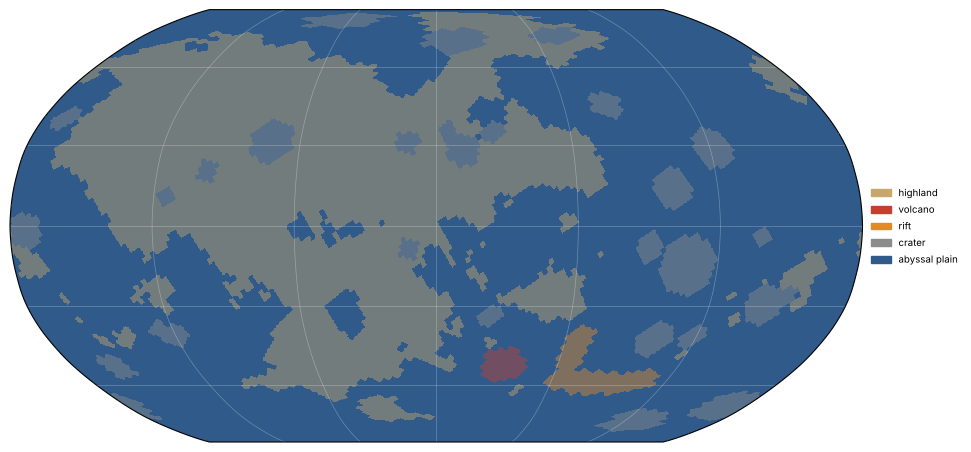

In [9]:
plot_map(europa, "terrain", "robinson", title="");

## 5. A habitable moon from the archetype

The `habitable_moon` archetype draws a moon with open oceans and its parent. Regular moons need parents of several Jupiter masses; captured moons orbit lighter giants, half of them retrograde. A standalone moon has no saved parent, so its system is drawn around the parent rebuilt from its parent section, with this moon alone.

Parent planet
  parent                      parent, 779 M⊕, 13.3 R⊕  [archetype]
  orbit about the parent      943,943 km (11.2 parent radii), e = 0.0000  [archetype]
  period about the parent     3.784 days
  stable limit                60 parent radii  [heuristic]
  fluid Roche limit           1.82 parent radii
  parent rotation             9.809 h  [archetype]
  moon's origin               captured  [archetype]
  starlight                   0.69 × Earth's; eclipses remove 0.2%, the parent reflects 0.43% more
  parent's glow               0.33 W/m² absorbed (parent at 235 K)  [derived]
  tidal heat                  0 TW, 0 W/m²  [heuristic]
  tidal response              k₂/Q 0.00689  [heuristic]
  eccentricity damping        e 0.0047 → 0: free eccentricity damped by the moon's tides in 0.00101 Gyr (no resonance holds it)  [heuristic]
  parent's magnetosphere      standoff 50.8 parent radii; the moon spends 100% of its orbit inside  [heuristic]

Atmosphere and surface
  atmosphere    

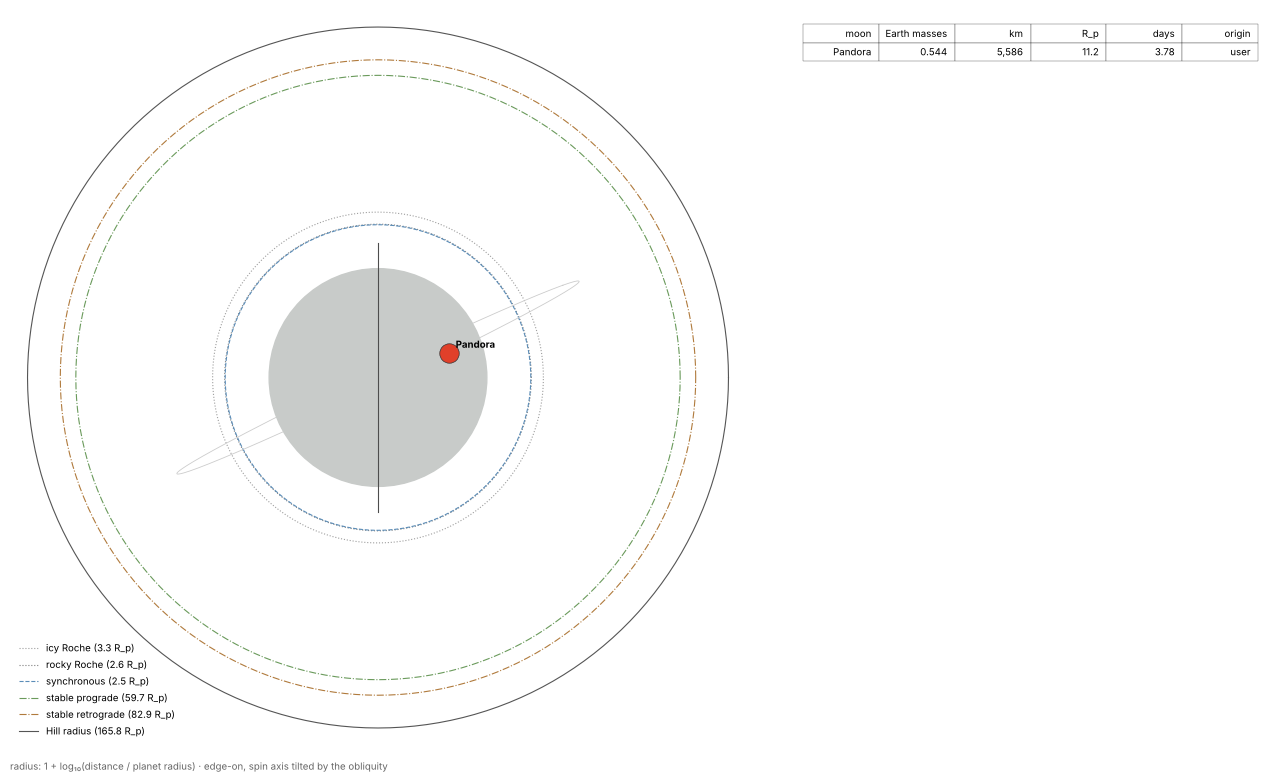

In [10]:
moon = generate_world(PlanetSpec.model_validate({"name": "Pandora", "seed": 3,
                                                 "priors": {"archetype": "habitable_moon"}}), "preview")
report = format_report(moon.state)
print(section(report, "Parent planet"), end="\n\n")
print(section(report, "Atmosphere and surface"))
parent = generate(rebuilt_parent_spec(moon.state, moon.spec))[0]
plot_system(parent, view="edge", highlight="Pandora", moon_worlds={"Pandora": moon});

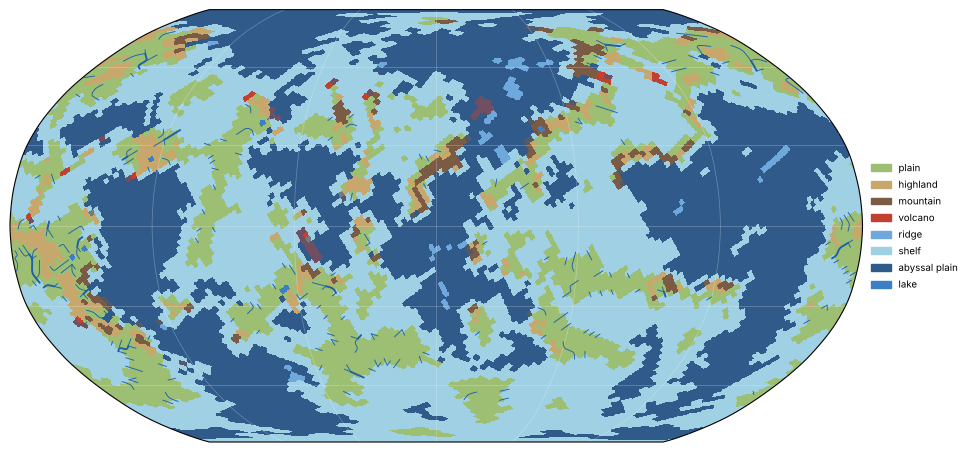

In [11]:
plot_map(moon, "terrain", "robinson", title="");

## 6. The system in 3D

`system_scene` shows the planet, rings and moons lit by the star. Light and shadows are computed per vertex: the rings' shadow on the planet, the planet's on the rings and moons, and moon shadows on both. Distances are compressed by default (true out past the rings, logarithmic beyond, moons enlarged); `scale="true"` keeps true proportions. Moons kept in the planet's folder are drawn with their own surfaces. `scene.show()` opens a window with a time slider, `scene.save_html(path)` writes an interactive page (vtk.js, ~9 MB) and `scene.save_movie(path)` an MP4 or GIF.

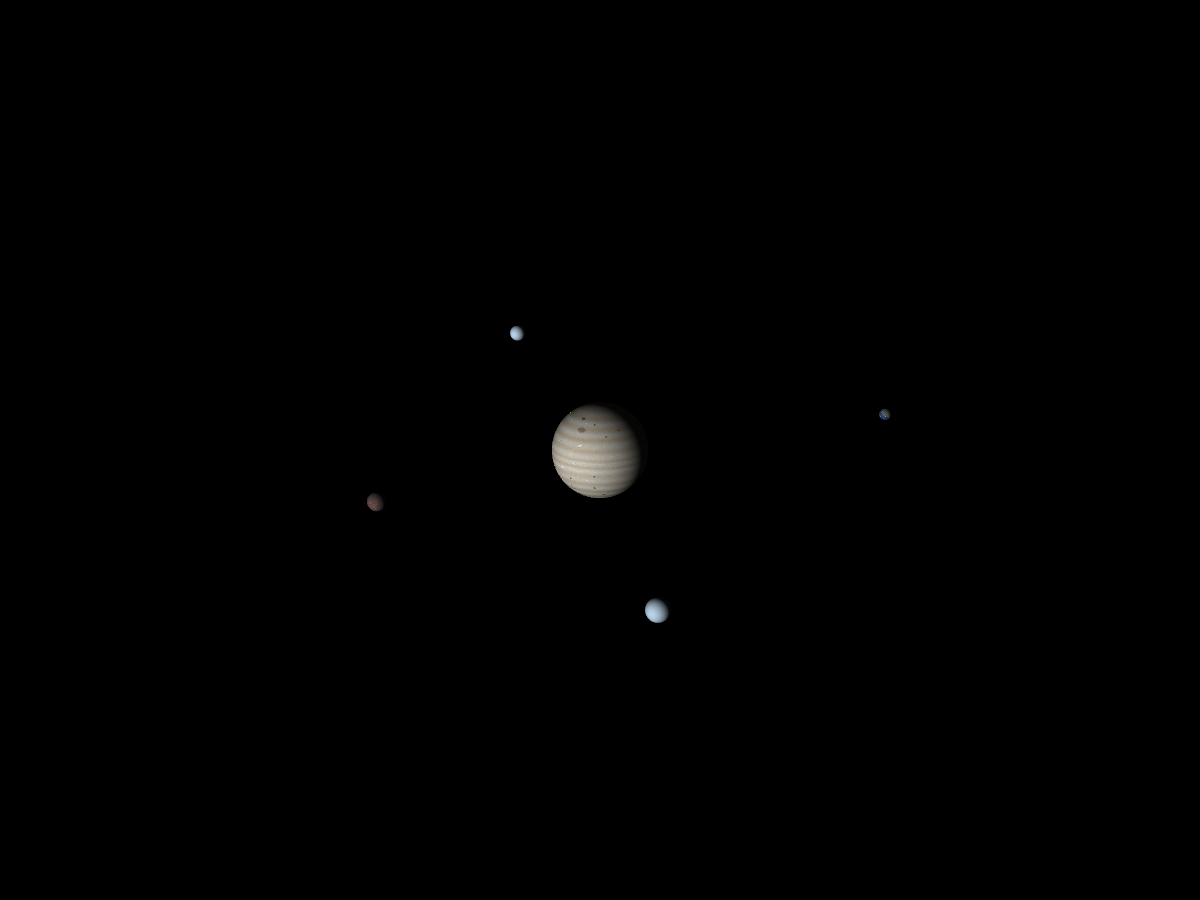

In [12]:
scene = system_scene(jupiter, folder=folder)
display(Image(filename=scene.screenshot(out / "jupiter.png", t_s=0.5 * 86400)))

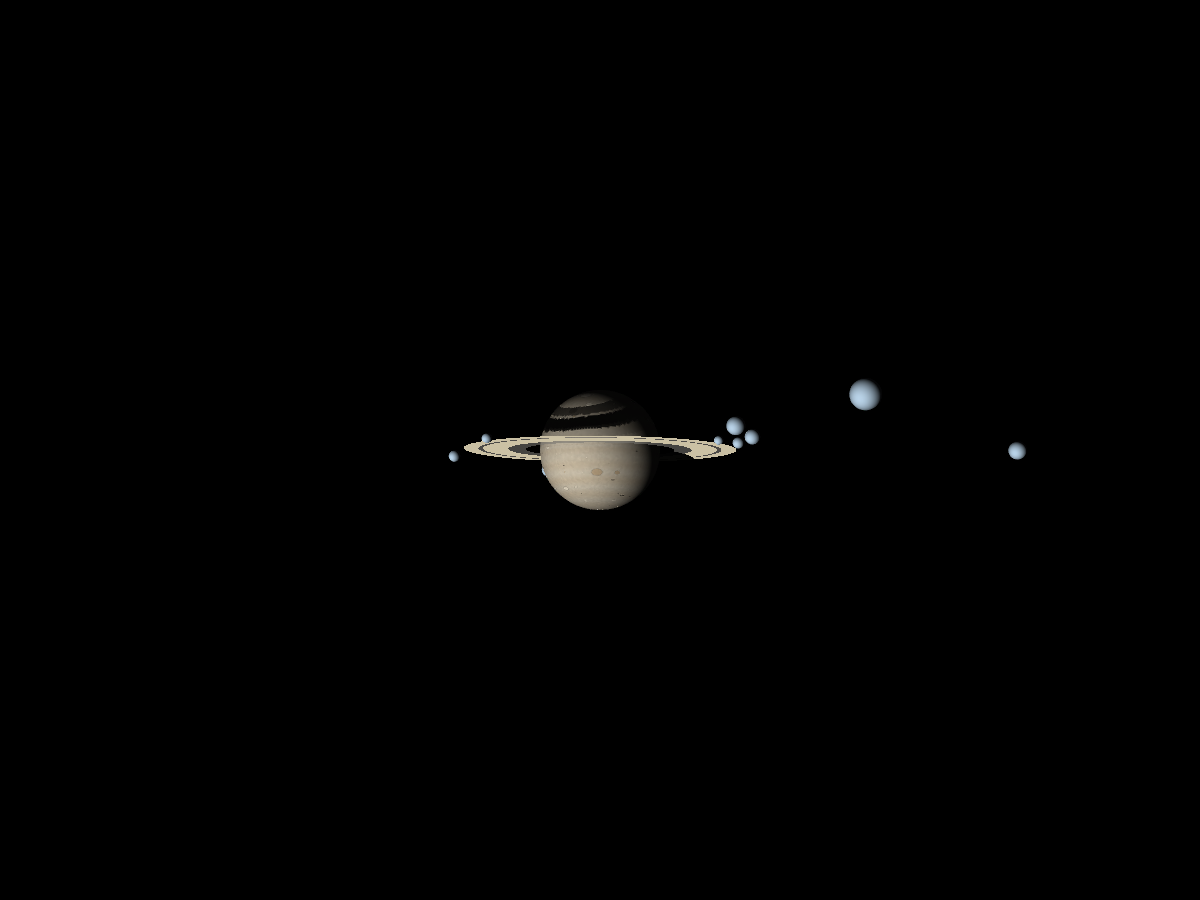

In [13]:
display(Image(filename=system_scene(saturn).screenshot(out / "saturn.png")))

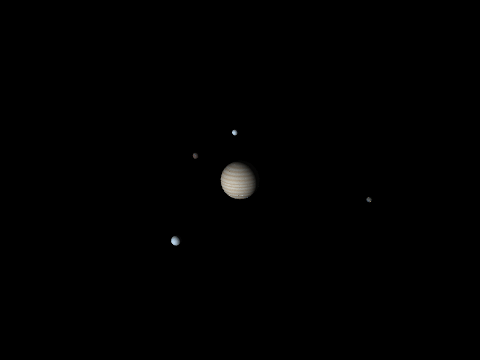

In [14]:
movie = scene.save_movie(out / "jupiter.gif", duration_s=3.55 * 86400, frames=24, window_size=(480, 360))
display(Image(filename=movie))

## 7. The command line

`worldgen moon` builds a moon and keeps it with its planet; `worldgen system` draws the diagram, or the 3D scene with `--3d` (an image, an HTML page, an MP4 or a GIF; without a file a window opens). A moon's folder draws its parent's system with the moon marked.

  1  Io                   0.015 M⊕      6.0 R_p  user       kept
  2  Europa             0.00804 M⊕      9.6 R_p  user       kept
  3  Ganymede            0.0248 M⊕     15.3 R_p  user     
  4  Callisto             0.018 M⊕     26.9 R_p  user     



system diagram written to /tmp/worldgen_giants_ttzunz7n/europa_system.png



system scene written to /tmp/worldgen_giants_ttzunz7n/jupiter_scene.png



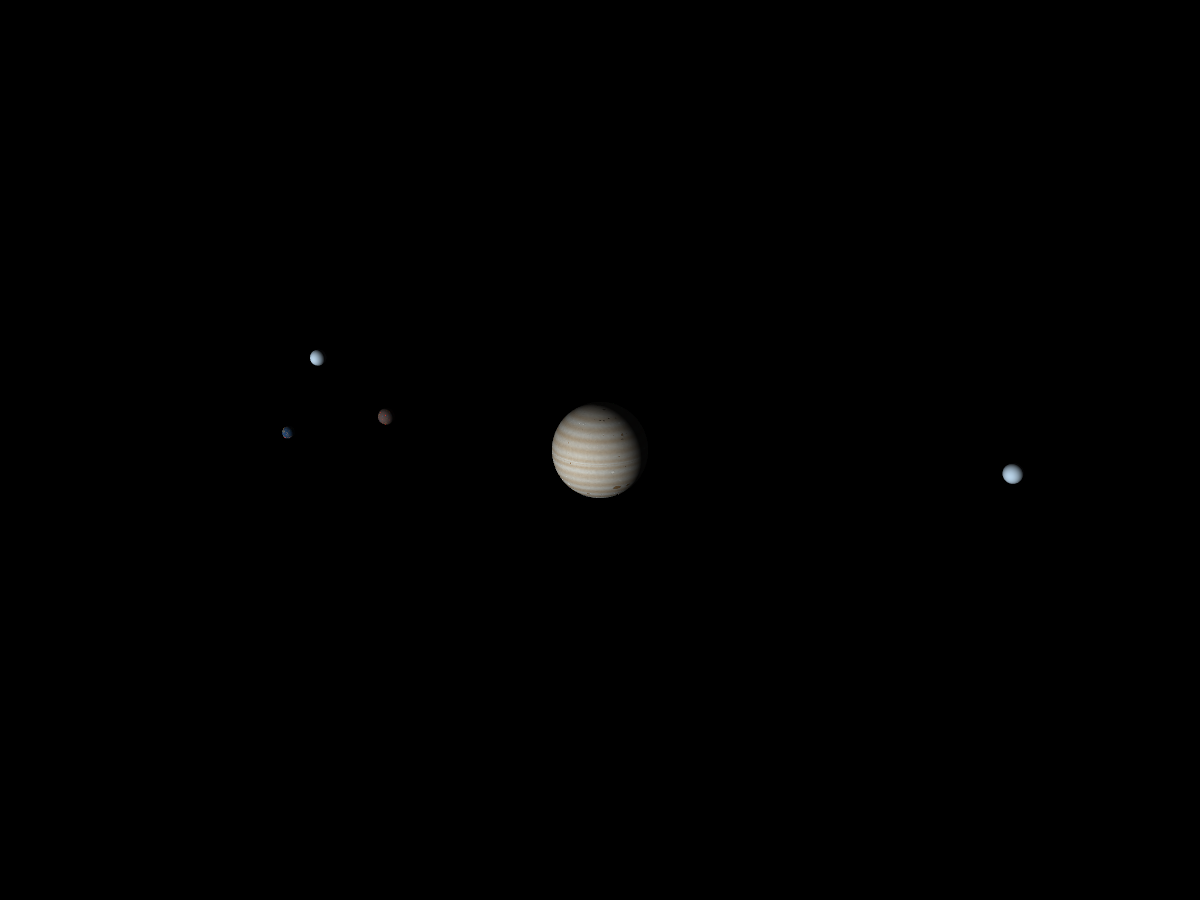

In [15]:
def worldgen(*args):
    result = subprocess.run([sys.executable, "-m", "worldgen.cli", *map(str, args)], capture_output=True, text=True)
    print(result.stdout[-1500:] or result.stderr[-1500:])


worldgen("moon", folder)
worldgen("system", folder / "moons" / "01_europa", out / "europa_system.png", "--view", "edge")
worldgen("system", folder, out / "jupiter_scene.png", "--3d", "--time", "2")
display(Image(filename=out / "jupiter_scene.png", width=600))

## 8. Solar System validation

`scripts/validate_solar_system.py` builds the four giants, compares drawn systems over many draws with the Solar System's, and builds Io, Europa, Ganymede, Callisto, Enceladus, Titan, Triton and the Moon from their real orbits. Each check names its source.

In [16]:
result = subprocess.run([sys.executable, "../scripts/validate_solar_system.py", "--seeds", "200"],
                        capture_output=True, text=True, env={**os.environ, "PYTHONPATH": ".."})
print(result.stdout)

ok   Jupiter: effective temperature (K)                                           125.0  vs 124.7 ± 3.0                  [Li et al. 2018 (A 0.503, 7.485 W/m² internal)]
ok   Jupiter: Bond albedo                                                          0.46  vs 0.503 ± 0.06                 [Li et al. 2018 (A 0.503, 7.485 W/m² internal)]
ok   Saturn: effective temperature (K)                                             95.1  vs 96.3 ± 3.0                   [Wang et al. 2024 (A 0.41, 4.88 W/m² emitted)]
ok   Saturn: Bond albedo                                                           0.46  vs 0.41 ± 0.06                  [Wang et al. 2024 (A 0.41, 4.88 W/m² emitted)]
ok   Uranus, Neptune: effective temperature range over 20 seeds (K)           48.8–65.0  vs 59.1 and 59.3 inside         [Pearl et al. 1990 via Irwin et al. 2025; Guillot & Gautier 2015 via Scheibe et al. 2021]
ok   Uranus: Bond albedo                                                            0.3  vs 0.29–0.35              